# Pilot1 learning validation and memory diagnostics

Validate learning adaptation first. Check memory sensitivity next. Interpret possible memory condition differences in light of both checks.

| Intended comparison | Difference |
| --- | --- |
| Uncertainty regime | HighVol plus lowSto minus lowVol plus highSto |
| Valence | Reward minus loss |

The occasional drone jumps are intentional. Volatility and stochasticity vary together, so the regime contrast cannot identify their separate effects. Participants are the sampling units. No significance threshold or outcome based exclusion is applied.

Every data panel reports its numerical Δ underneath. The direction is stated in the footer. The 95% interval resamples paired participant differences, with equal block weights. Four condition panels show the contrasts within each valence and within each regime. Fixed design arrays and allocation counts have descriptive differences without sampling intervals.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'static/task/stimuli.js').exists())
for path in [ROOT / 'analysis/drone_task', ROOT / 'analysis']:
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
import Pilot1_analysis as report
%matplotlib inline
plt.rcParams.update({'font.size': 10, 'axes.titlesize': 11})
pd.set_option('display.max_colwidth', 90)
BATCH = ROOT / 'analysis/data/Pilot1'
result = report.run_comparisons(BATCH)


(node:22656) Warning: The 'NO_COLOR' env is ignored due to the 'FORCE_COLOR' env being set.
(Use `node --trace-warnings ...` to show where the warning was created)


## Evaluation sequence

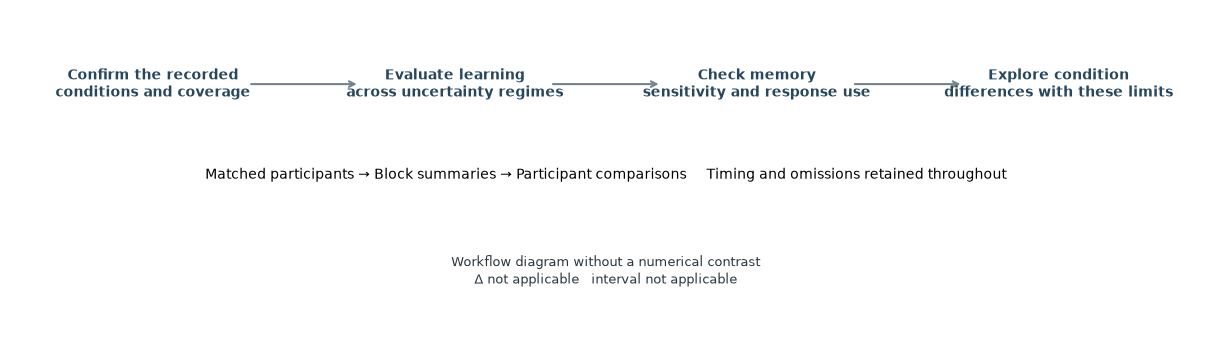

In [2]:
display(result['figures']['calculation_flow'])

## Recording foundation

One completed production run per matched submission. Original downloads, partial runs and checkpoints remain preserved. Recording delivery and behavioral validation are separate questions. Detailed assignment checks appear in the appendix.

In [3]:
display(pd.DataFrame({'Recorded material': ['Matched participants', 'Game turns', 'Intended memory pairs', 'Condition blocks', 'Passed assignment check families'],
    'Observed': [result['summary']['participants'], len(result['tables']['encoding']), len(result['tables']['memory']), len(result['condition']), int(result['randomization']['checks'].status.eq('Pass').sum())]}))

,Recorded material,Observed
0,Matched participants,15
1,Game turns,3000
2,Intended memory pairs,840
3,Condition blocks,60
4,Passed assignment check families,16


## Learning and tracking

The primary validation question is whether participants update more strongly in highVol plus lowSto than in lowVol plus highSto. Tracking difficulty is supporting context.

### Prediction error and next update

| Symbol | Observed quantity |
| --- | --- |
| $c_{ibt}$ | Collector position for participant $i$, block $b$, turn $t$ |
| $y_{ibt}$ | Supply landing position observed after that prediction |
| $z_{ibt}$ | True hidden drone position, used only for tracking accuracy |

All positions use the same rail coordinates from 0 to 100.

$$
PE_{ibt}=y_{ibt}-c_{ibt}
\qquad
U_{ibt}=c_{ib,t+1}-c_{ibt}
$$

Current supply error → Collector change on the next turn → One regression per participant and block.

### Block learning rate

$$
U_{ibt}=a_{ib}+\beta_{ib}PE_{ibt}+\epsilon_{ibt}
$$

$$
\widehat\beta_{ib}=
\frac{\sum_t(PE_{ibt}-\overline{PE}_{ib})(U_{ibt}-\overline U_{ib})}
{\sum_t(PE_{ibt}-\overline{PE}_{ib})^2}
$$

The learning rate shown is the ordinary least squares slope with a fitted intercept. Each 50 turn block supplies 49 consecutive transitions. Zero updates remain included and updates never cross blocks. Slopes are not clipped to zero through one.

For example, collector 40 → supply landing 50 → next collector 46 gives $PE=10$ and $U=6$. The block estimate pools all 49 error and update pairs rather than averaging individual $U/PE$ ratios. It measures descriptive error driven updating rather than a recovered latent learning parameter.

### Tracking accuracy

$$
\mathrm{TrackingError}_{ib}=\frac{1}{50}\sum_{t=1}^{50}|c_{ibt}-z_{ibt}|
$$

Tracking error uses the hidden drone position and is measured in percentage points. Lower error means closer tracking. A higher learning rate means stronger updating, which is not automatically better tracking.

### Comparisons and uncertainty

Let $H$ denote highVol plus lowSto and $L$ denote lowVol plus highSto.

$$
\overline\beta_{i,H}=
\frac{\widehat\beta_{i,\mathrm{reward},H}+\widehat\beta_{i,\mathrm{loss},H}}{2}
\qquad
D_{i,\mathrm{regime}}=\overline\beta_{i,H}-\overline\beta_{i,L}
$$

$$
D_{i,\mathrm{valence}}=
\frac{\widehat\beta_{i,\mathrm{reward},H}+\widehat\beta_{i,\mathrm{reward},L}}{2}
-
\frac{\widehat\beta_{i,\mathrm{loss},H}+\widehat\beta_{i,\mathrm{loss},L}}{2}
\qquad
\overline D=\frac{1}{15}\sum_{i=1}^{15}D_i
$$

Bar heights average participant summaries with equal block weighting. Whiskers show 95 percent intervals from 10,000 participant bootstrap resamples. Thin paired points retain individual differences. Contrast intervals resample the paired participant differences.

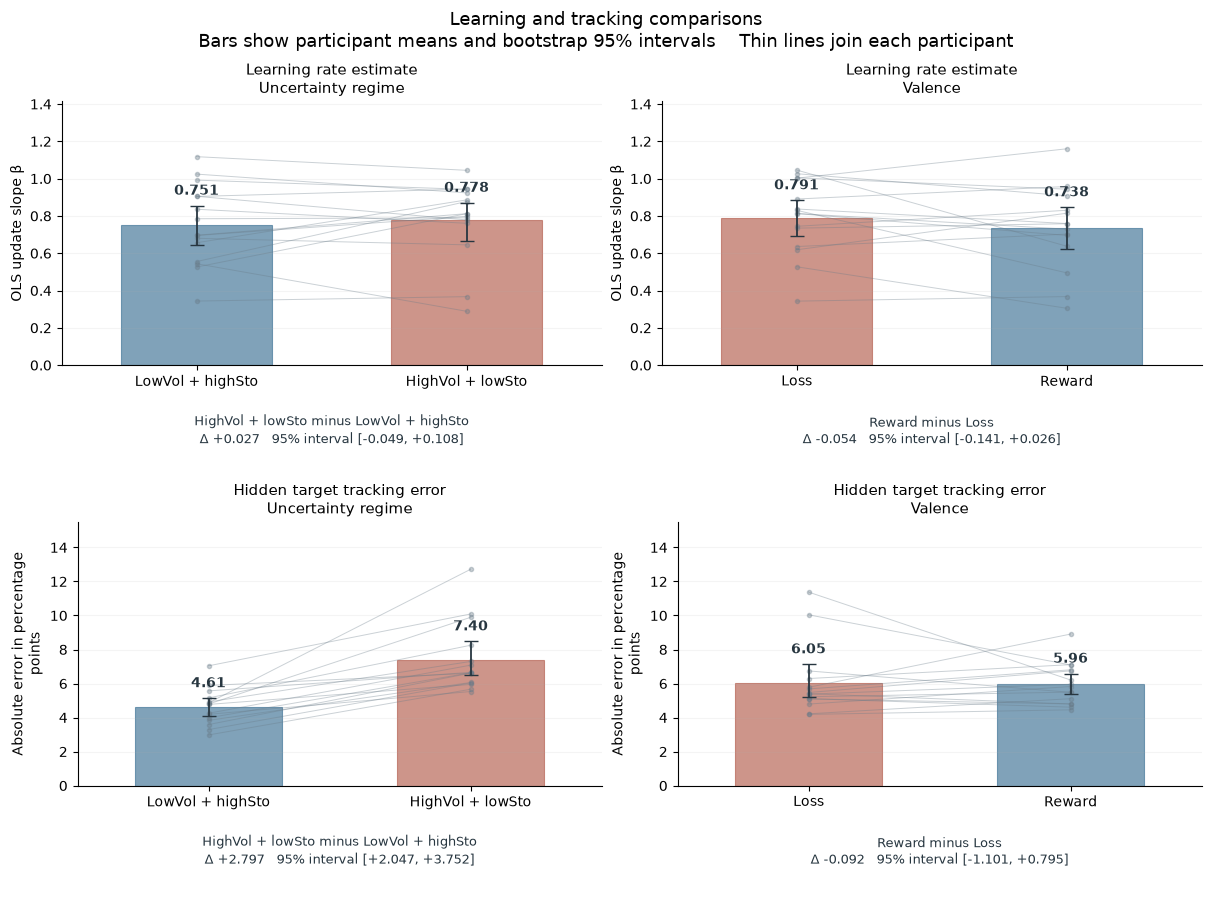

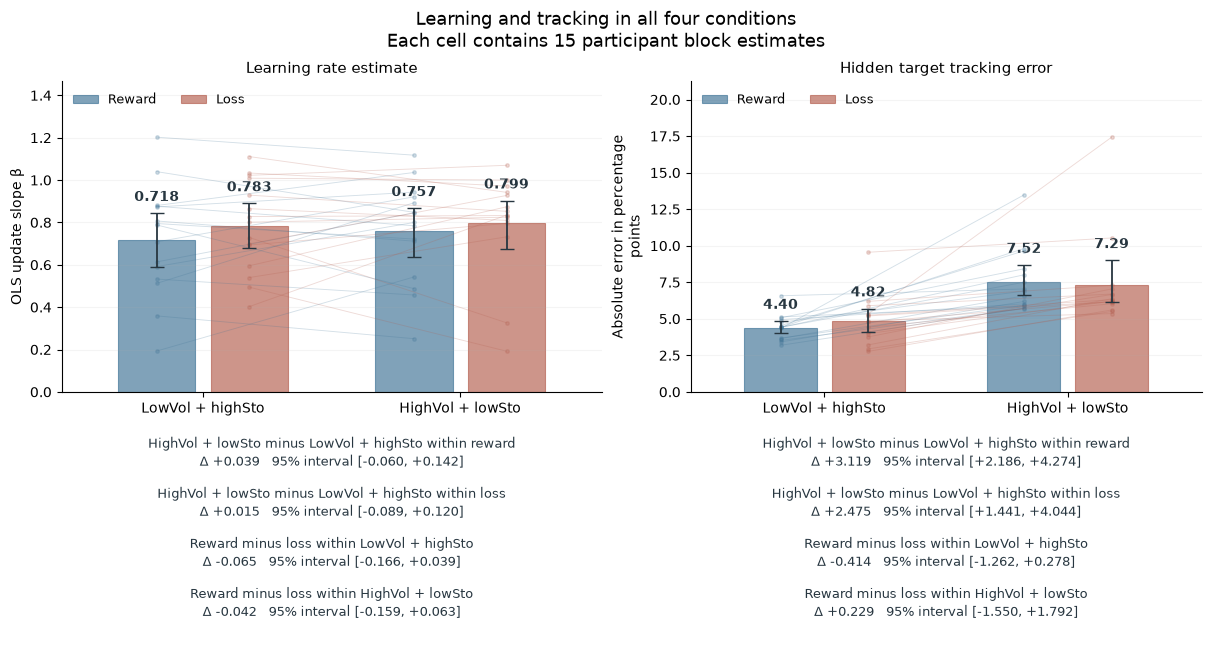

,comparison,outcome,First level,Second level,Difference and 95% interval,Higher / lower / tied,Participants
0,Uncertainty regime,Error driven update gain,0.751,0.778,"+0.027 [-0.049, +0.108]",8 / 7 / 0,15
1,Uncertainty regime,Hidden target tracking error,4.608,7.405,"+2.797 [+2.047, +3.752]",15 / 0 / 0,15
2,Valence,Error driven update gain,0.791,0.738,"-0.054 [-0.141, +0.026]",7 / 8 / 0,15
3,Valence,Hidden target tracking error,6.053,5.960,"-0.092 [-1.101, +0.795]",9 / 6 / 0,15


In [4]:
display(result['figures']['learning_comparisons'])
display(result['figures']['learning_condition_bars'])
display(report.display_effects(result, ['update_slope', 'target_mae_pp']))

### Published learning benchmarks

The published participant coefficients were recomputed from the authors' data with the same type of block OLS estimator. Their random walk and your intended jump task are different designs, so the published contrast is a descriptive benchmark. The published design crosses volatility and stochasticity independently. Pilot1 compares coupled regimes across reward and loss. A positive pilot mean alone does not establish joint uncertainty inference.

[Published estimator and data](https://github.com/payampiray/stovol-learning/tree/71121dc4ca34aee35c619a6e9cb380a18d0411e3) · [Offline reference provenance](references/README.md)

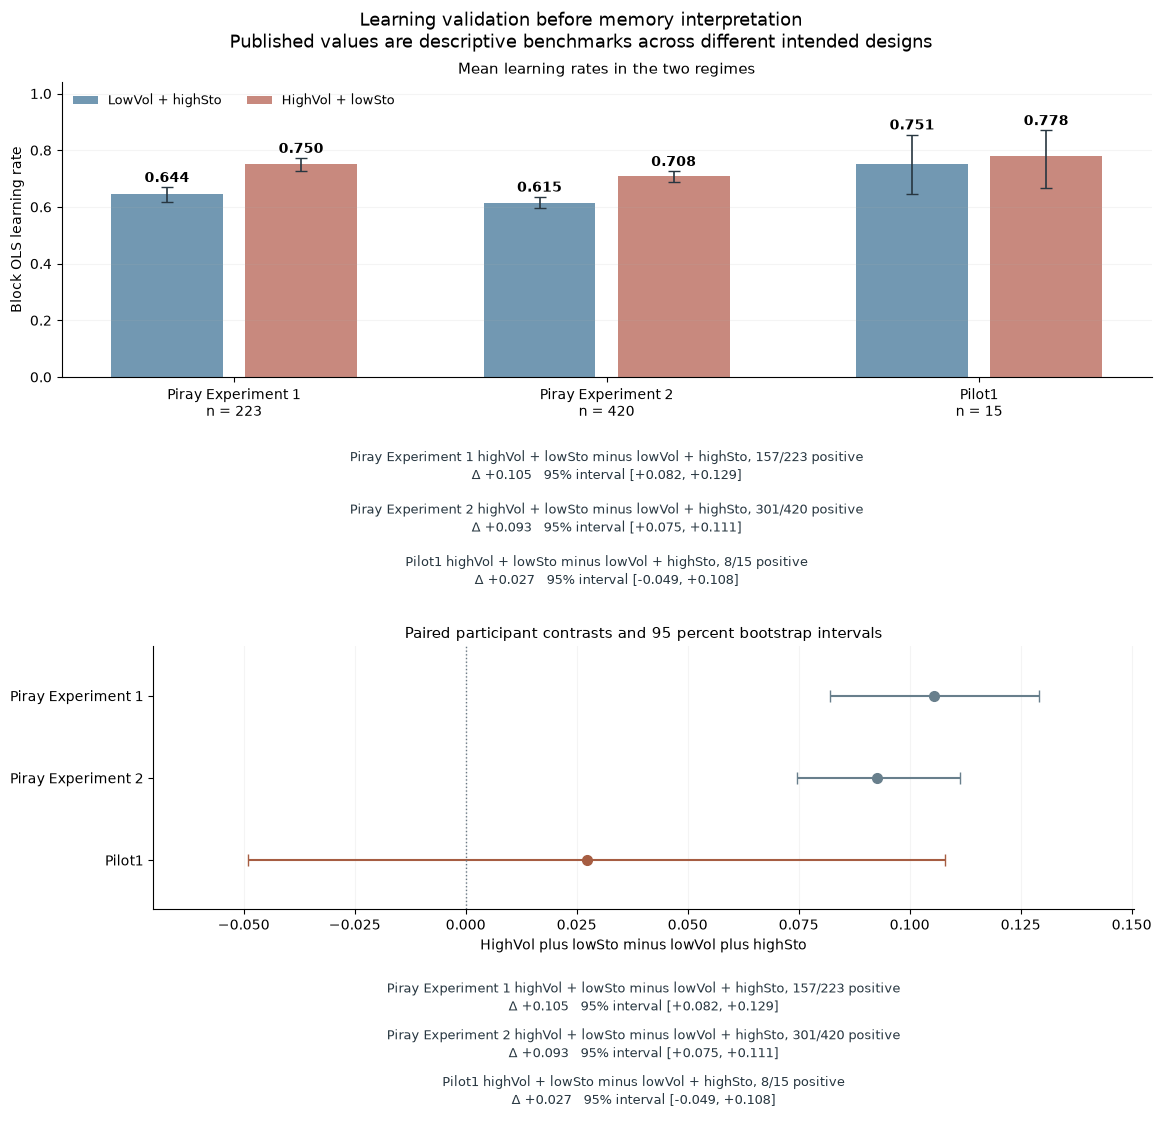

,Validation question,Observed or design fact,Interpretation
0,Expected regime ordering,Observed mean difference +0.027,Positive mean alone is not joint uncertainty inference
1,Participant consistency,8 of 15 positive,Inspect individual directions alongside the mean
2,Estimate uncertainty,95 percent interval -0.049 to +0.108,A small pilot can accommodate several underlying magnitudes


In [5]:
display(result['figures']['learning_replication_benchmark'])
display(result['learning_validation']['interpretation'].iloc[:3].reset_index(drop=True))

### Intended design context

The fixed jump schedule remains unchanged. Realised geometry is calculated from the delivered positions. Supply spread uses population standard deviations for both datasets, keeping the comparison convention consistent. Nominal noise codes are not empirical variance estimates.

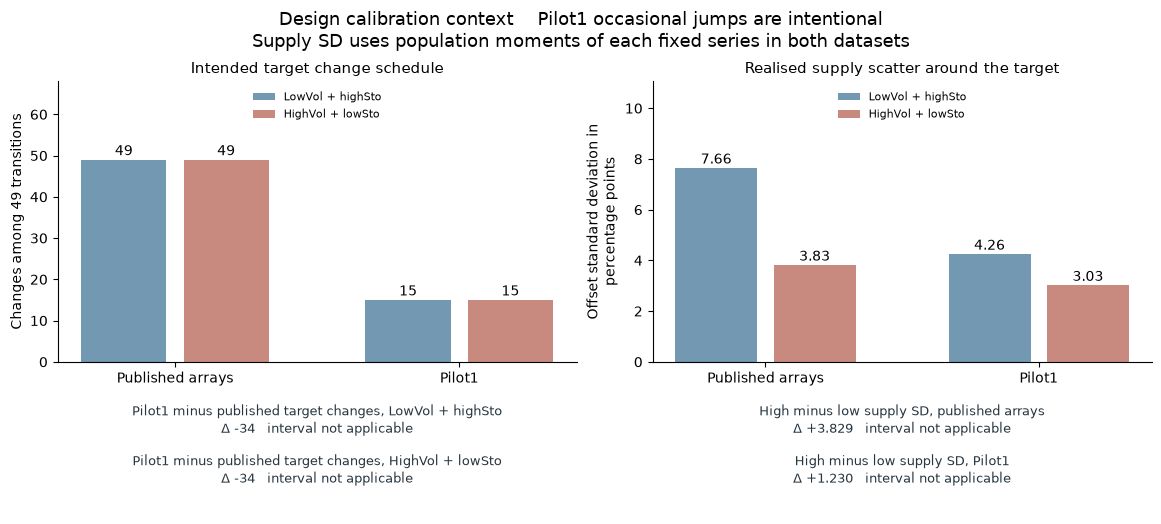

In [6]:
display(result['figures']['learning_design_geometry'])

### Tracking across turns

Both Pilot1 regimes use the same 15 change positions. Different tracking errors show different task demands; they do not by themselves demonstrate uncertainty tracking.

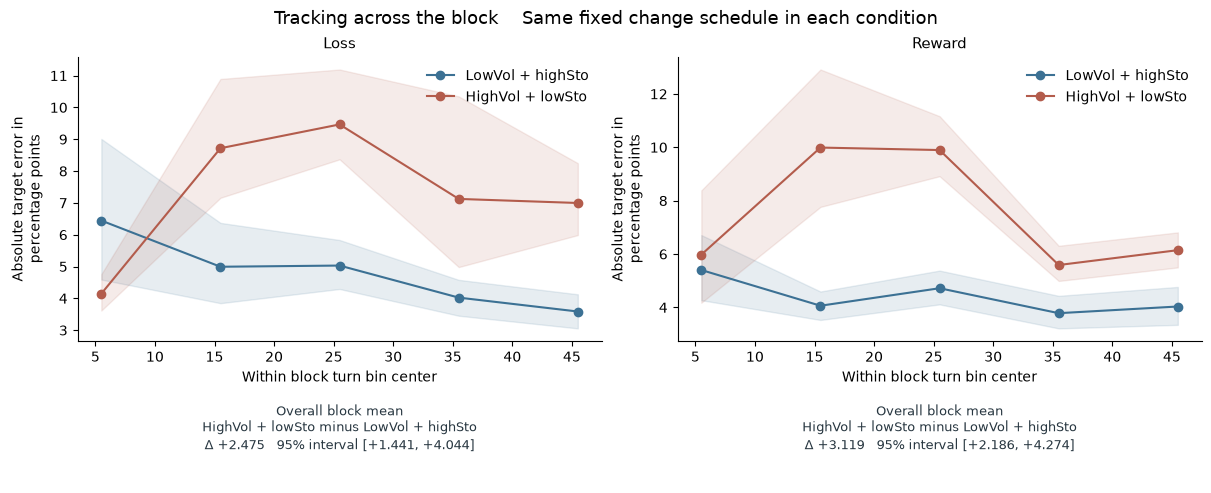

In [7]:
display(result['figures']['tracking_timecourse'])

## Memory measurement sensitivity

Before interpreting condition differences, check whether responses discriminate actual order, separation and position.

| Measure | Calculation and reference |
| --- | --- |
| Temporal order | Correct divided by answered pairs at each gap, compared with 50 percent |
| Temporal distance | Mean slider rating at gaps of one and two intervening items |
| True placement | $100(p-i)/(j-i)$ for probe $p$ between reference turns $i$ and $j$ |
| Placement error | Response minus true position, in percentage points |
| Placement absolute error | Mean absolute placement error |

$$
D_{\mathrm{distance},ib}=\overline R_{ib,\mathrm{gap}\,2}-\overline R_{ib,\mathrm{gap}\,1}
$$

$$
D_{\mathrm{placement},ib}=\overline R_{ib,\mathrm{true}\,66.67}-\overline R_{ib,\mathrm{true}\,33.33}
$$

Zero indicates no mean differentiation. Accurate mean placement separation is 33.33 percentage points. Distance ratings have no equivalent fixed numerical ideal.

Calculate stratum means within each participant block → Retain paired stratum support → Equal block averages within each person → Participant comparisons. No response is imputed. Fixed pair positions mean these are diagnostic associations.

In [8]:
diagnostics = result['memory_diagnostics']['summary'].copy()
diagnostics['Estimate'] = diagnostics.apply(lambda row: f'{row["mean"]:.1%}' if row.metric == 'order_accuracy' else f'{row["mean"]:.2f}', axis=1)
diagnostics['Reference'] = diagnostics.apply(lambda row: '50%' if row.metric == 'order_accuracy' else f'{row.reference:.2f}', axis=1)
display(diagnostics[['diagnostic','stratum','Estimate','unit','Reference','n']].rename(columns={'diagnostic':'Diagnostic','stratum':'Actual separation or position','unit':'Unit','n':'Participants'}))

,Diagnostic,Actual separation or position,Estimate,Unit,Reference,Participants
0,Order accuracy with 1 intervening items,Gap 1,51.4%,Fraction correct,50%,15
1,Order accuracy with 2 intervening items,Gap 2,50.1%,Fraction correct,50%,15
2,Temporal distance sensitivity,All conditions,-1.22,Gap two minus gap one in rating units,0.00,15
3,Temporal placement discrimination,All conditions,-0.71,Late minus early response in percentage points,0.00,15
4,Mean reported temporal position,True 33.3%,53.11,Percent of reference interval,33.33,15
5,Mean reported temporal position,True 50.0%,50.88,Percent of reference interval,50.00,15
6,Mean reported temporal position,True 66.7%,52.40,Percent of reference interval,66.67,15


### Temporal order by actual gap

Accuracy above chance and differences between gaps are separate checks. Both uncertainty regimes and both valences remain visible on matching axes.

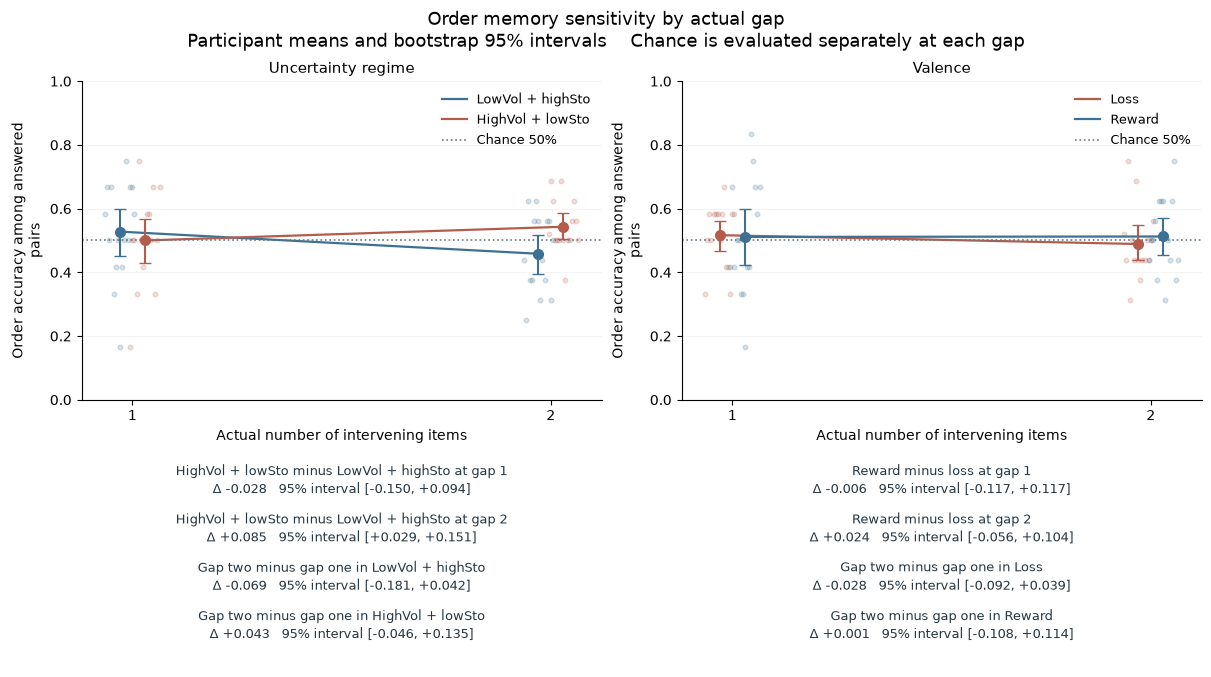

,Intervening items,intended,answered,unanswered
0,1.0,360,355,5
1,2.0,480,475,5


In [9]:
display(result['figures']['order_gap_diagnostic'])
order_support = result['memory_diagnostics']['support'].loc[lambda q: q.stage.eq('order')]
display(order_support.groupby('stratum')[['intended','answered','unanswered']].sum().rename_axis('Intervening items').reset_index())

### Distance and placement calibration

Higher distance ratings mean greater reported separation. They represent better discrimination only when they distinguish the actual gaps. Placement should distinguish the true early, middle and late positions.

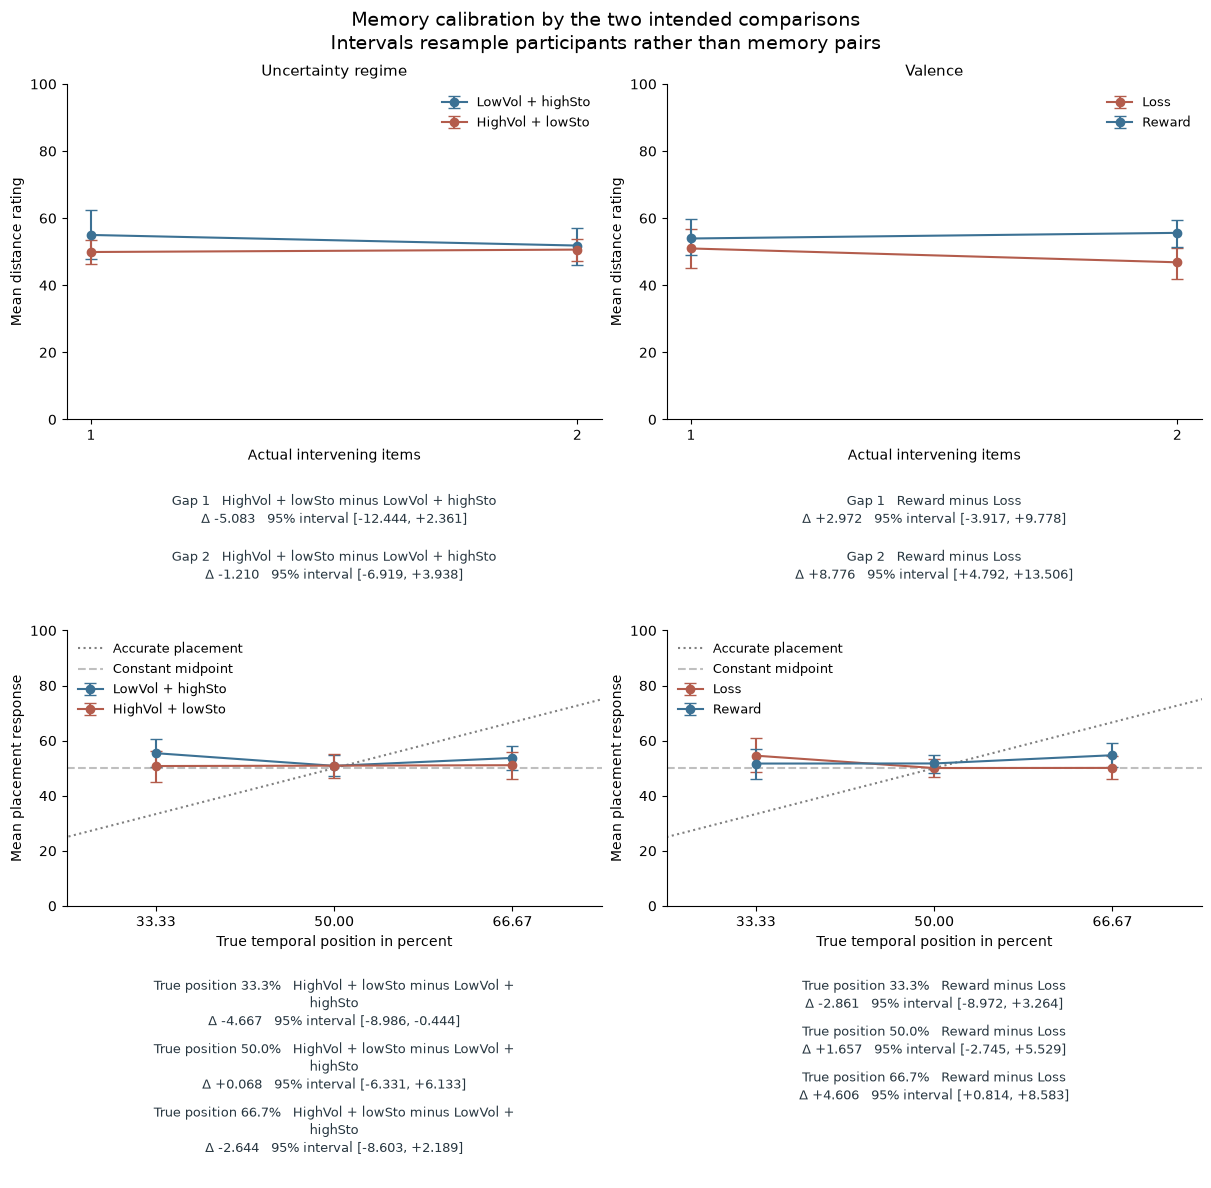

In [10]:
display(result['figures']['memory_calibration'])

### Discrimination between temporal positions

These comparisons ask whether sensitivity changes across conditions, separately from an overall shift toward higher ratings. Each line connects one participant's two condition summaries.

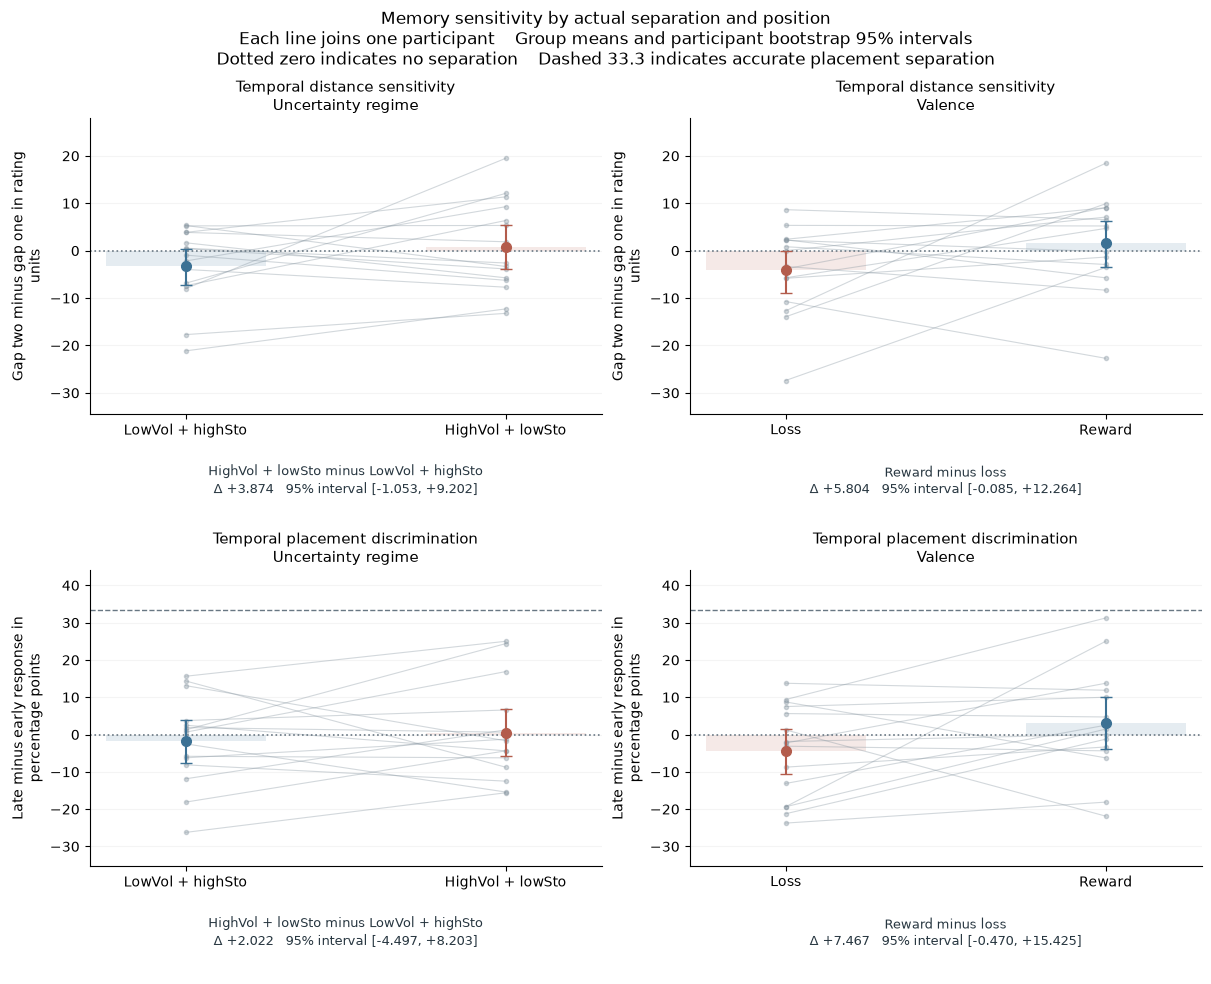

,Comparison,Diagnostic,Condition difference,95% interval,Paired participants
0,Uncertainty regime,Distance gap sensitivity,3.87,"[-1.05, +9.20]",15
1,Uncertainty regime,Placement discrimination,2.02,"[-4.50, +8.20]",15
2,Valence,Distance gap sensitivity,5.80,"[-0.08, +12.26]",15
3,Valence,Placement discrimination,7.47,"[-0.47, +15.43]",15


In [11]:
display(result['figures']['memory_discrimination'])
sensitivity = result['memory_diagnostics']['effects'].copy()
sensitivity['Diagnostic'] = sensitivity.metric.map({'distance_gap_difference':'Distance gap sensitivity','placement_discrimination':'Placement discrimination'})
sensitivity['95% interval'] = sensitivity.apply(lambda row: f'[{row.ci_low:+.2f}, {row.ci_high:+.2f}]', axis=1)
display(sensitivity[['comparison','Diagnostic','mean','95% interval','n']].rename(columns={'comparison':'Comparison','mean':'Condition difference','n':'Paired participants'}).round(2))

### Placement response distributions and strategy references

Each distribution is normalized within a participant block and true target position, then averaged with equal block and participant weighting. Different response counts do not become extra participant weight.

The table compares absolute placement error on the actual answered probes. Constant midpoint and uniform response strategies are descriptive references.

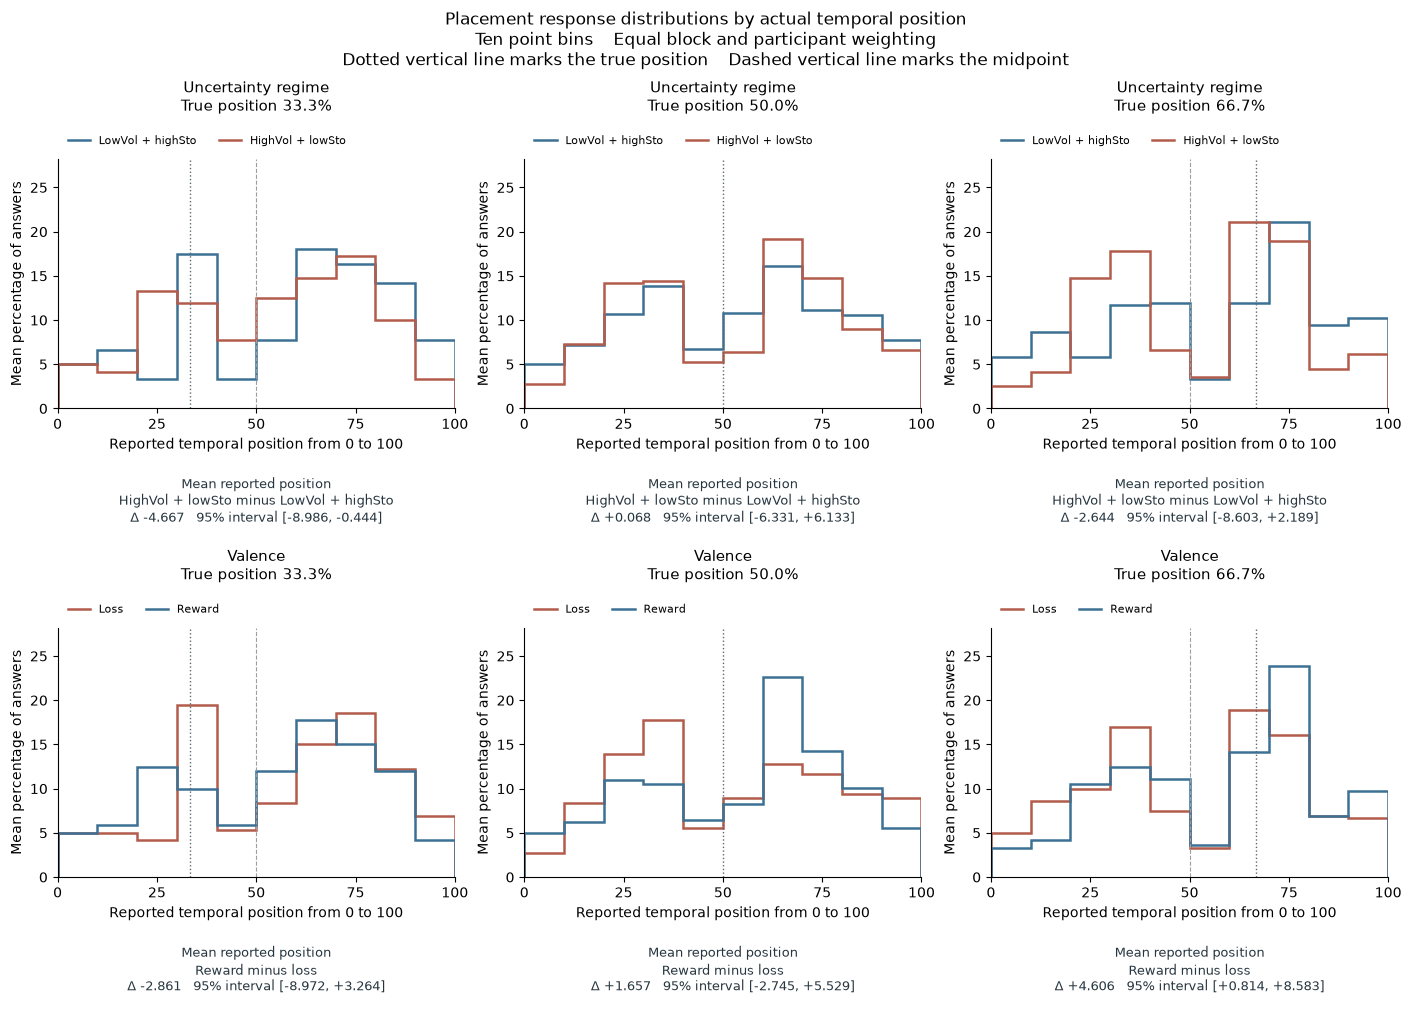

,Reference strategy,Absolute error in percentage points,ci_low,ci_high
0,Observed responses,24.210,20.309,28.496
1,Always choose the midpoint,9.518,9.441,9.618
2,Uniform random response expectation,26.586,26.574,26.603


In [12]:
display(result['figures']['placement_response_distributions'])
bench = result['benchmark_summary'].loc[lambda q: q.separation.eq('All answered') & q.metric.isin(['observed_mae_pp','constant_midpoint_mae_pp','uniform_rating_expected_mae_pp'])].copy()
bench['Reference strategy'] = bench.metric.map({'observed_mae_pp':'Observed responses','constant_midpoint_mae_pp':'Always choose the midpoint','uniform_rating_expected_mae_pp':'Uniform random response expectation'})
display(bench[['Reference strategy','mean','ci_low','ci_high']].rename(columns={'mean':'Absolute error in percentage points'}).round(3))

## Exploratory memory condition differences

Keep potentially interesting differences visible. Their interpretation as effects of uncertainty tracking remains provisional while learning validation and memory sensitivity are uncertain. Higher distance ratings are not automatically a memory advantage.

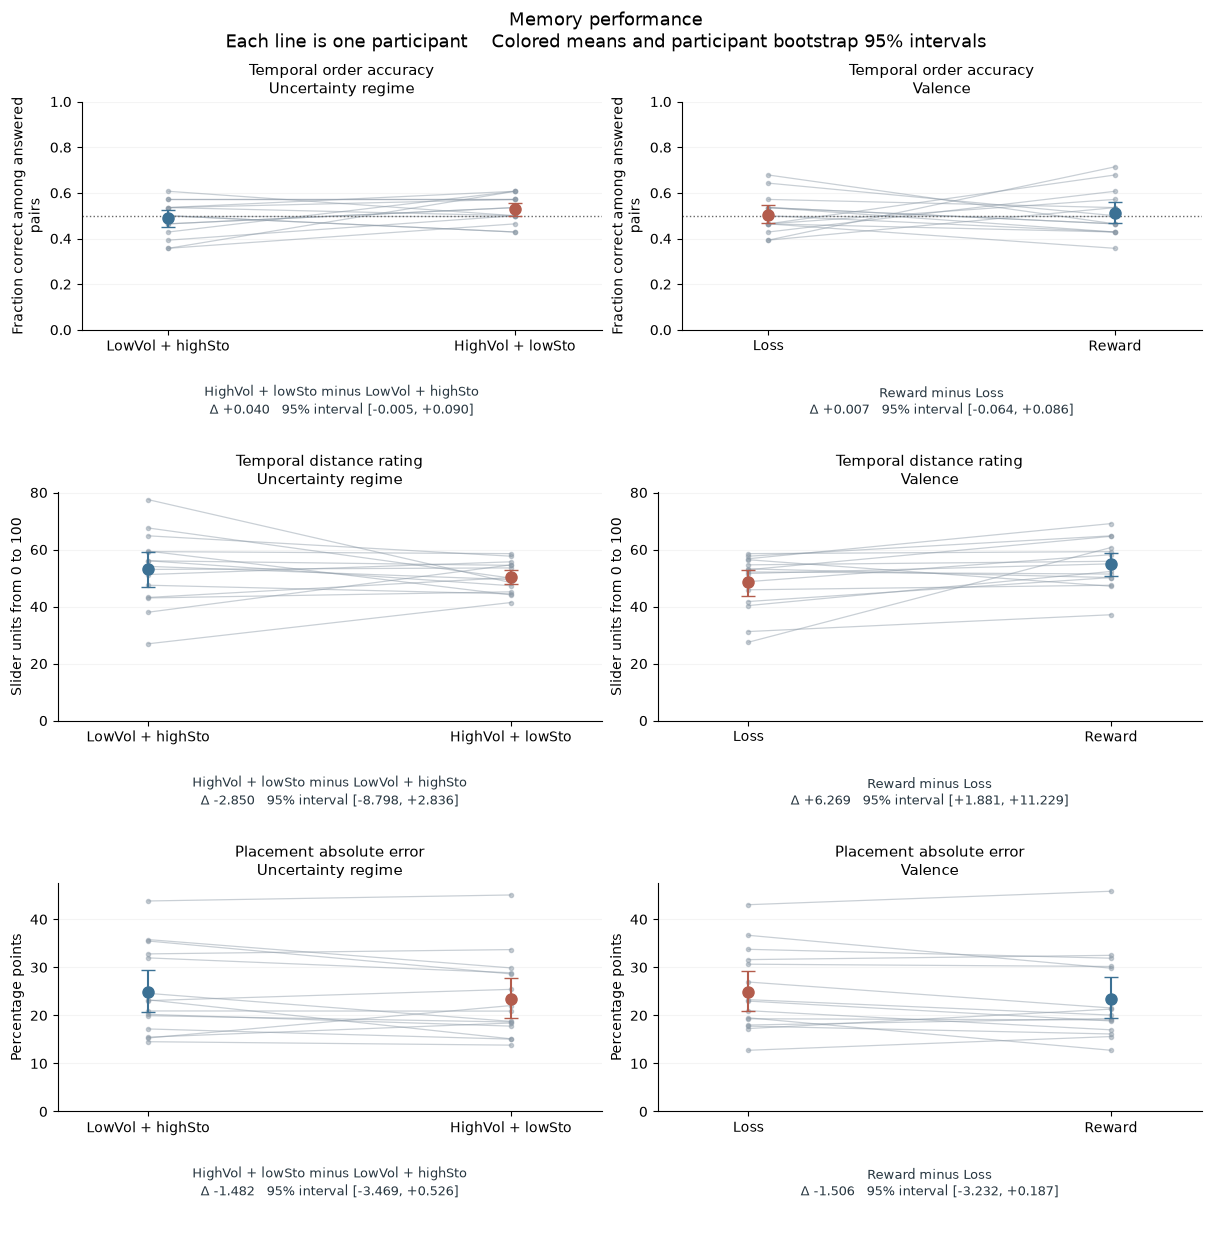

,comparison,outcome,First level,Second level,Difference and 95% interval,Higher / lower / tied,Participants
0,Uncertainty regime,Temporal order accuracy,0.488,0.529,"+0.040 [-0.005, +0.090]",8 / 4 / 3,15
1,Uncertainty regime,Temporal distance rating,53.195,50.345,"-2.850 [-8.798, +2.836]",6 / 9 / 0,15
2,Uncertainty regime,Placement absolute error,24.951,23.468,"-1.482 [-3.469, +0.526]",5 / 10 / 0,15
3,Valence,Temporal order accuracy,0.505,0.512,"+0.007 [-0.064, +0.086]",5 / 9 / 1,15
4,Valence,Temporal distance rating,48.636,54.905,"+6.269 [+1.881, +11.229]",12 / 3 / 0,15
5,Valence,Placement absolute error,24.962,23.457,"-1.506 [-3.232, +0.187]",5 / 10 / 0,15


In [13]:
display(result['figures']['memory_comparisons'])
display(report.display_effects(result, ['order_accuracy', 'distance_mean', 'placement_mae_pp']))

### Four condition memory patterns

Compare reward and loss within each regime. These descriptive patterns can guide follow up hypotheses without additional interaction significance tests.

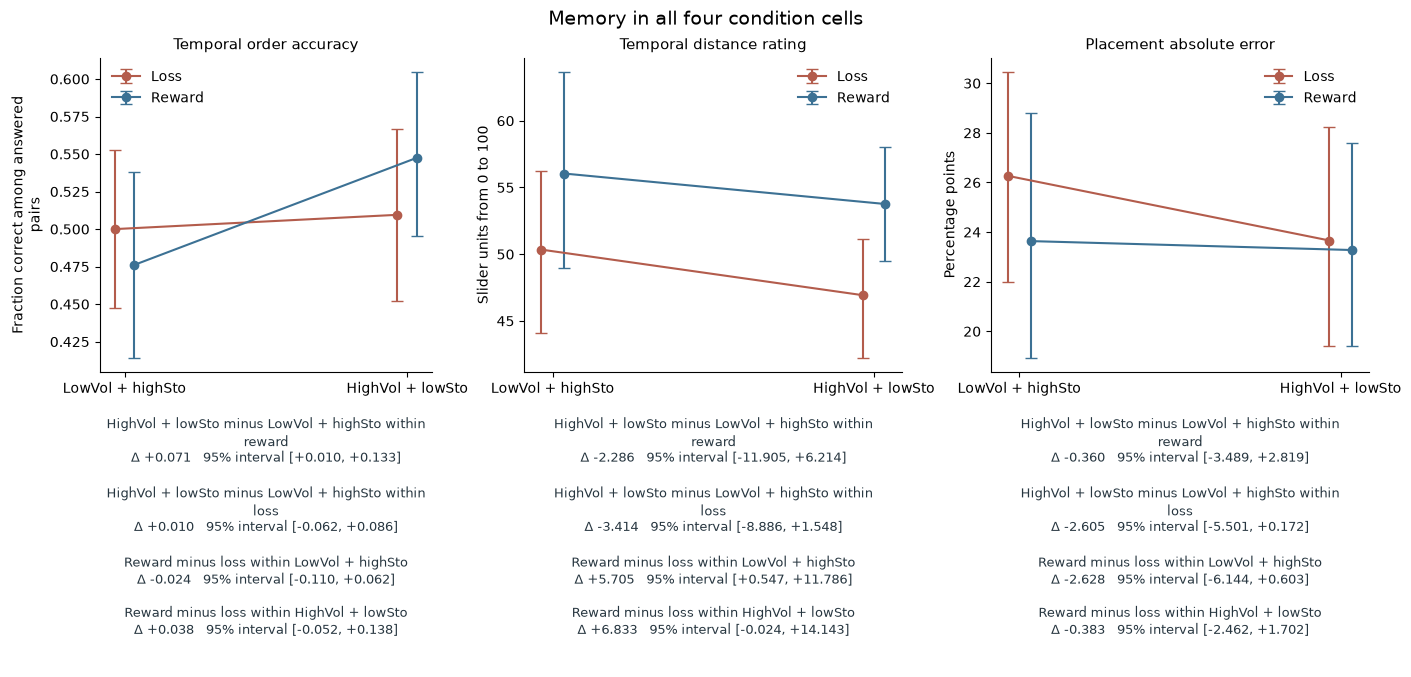

In [14]:
display(result['figures']['condition_cells'])

### Placement response biases

$$
\mathrm{Pull}=(R-T)\operatorname{sign}(50-T),\qquad T\ne50
$$

For true positions 33.33 and 66.67, always responding at 50 gives a pull of +16.67 percentage points. This is a constant midpoint reference. A generic no discrimination interpretation also depends on balanced target weighting. Mean differentiation is assessed directly above.

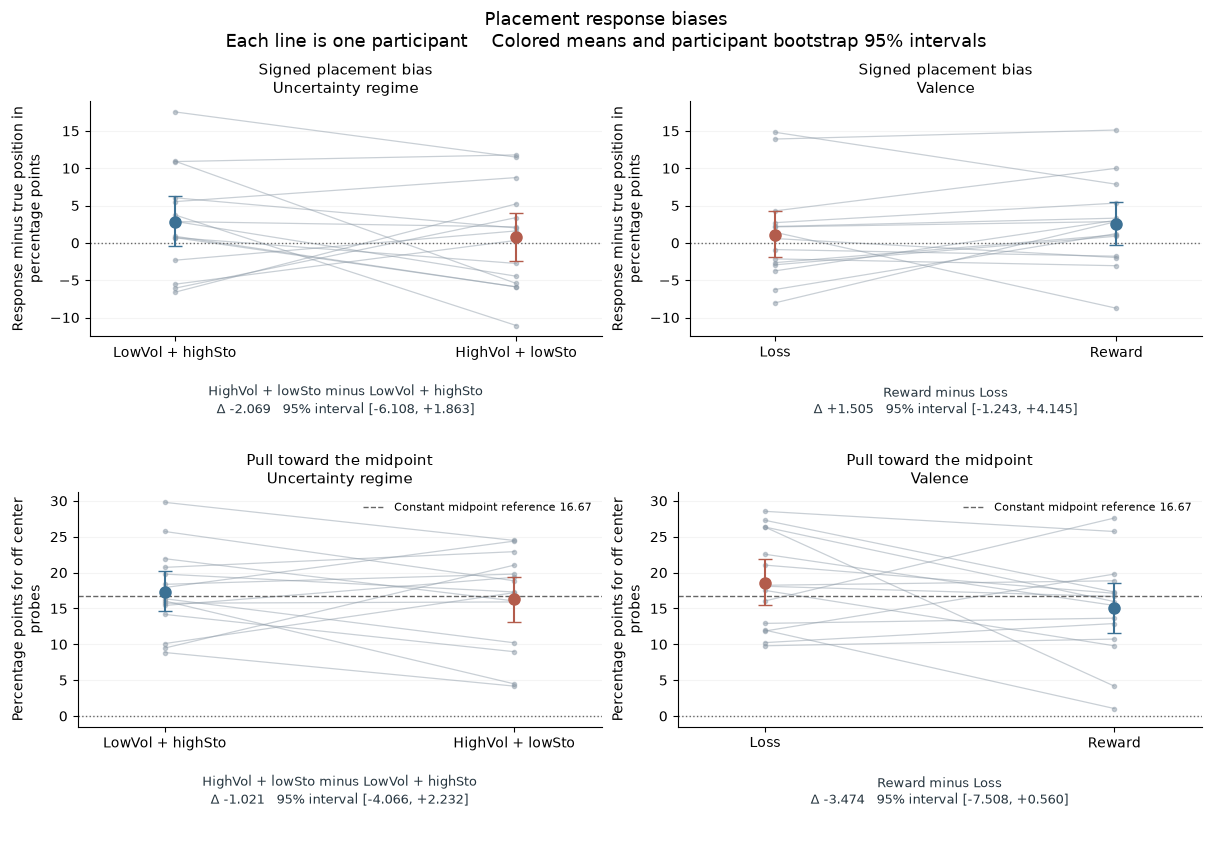

In [15]:
display(result['figures']['placement_bias_comparisons'])

## Timing and response usability

$$
RT_{\mathrm{initiation}}=t_{\mathrm{first\ response}}-t_{\mathrm{question\ onset}}
$$
$$
RT_{\mathrm{adjustment}}=t_{\mathrm{submission}}-t_{\mathrm{first\ response}}
$$

| Stage | Summary |
| --- | --- |
| Game | First collector movement latency among moving turns |
| Order | First valid arrow press on the successful attempt |
| Distance and placement | First arrow press and subsequent adjustment duration separately |
| Aggregation | Median answered RT per block, then equal block means within factor levels |

Automatic slider submission occurs 7 seconds after the first move. Manual confirmation may occur sooner. Total slider RT combines initiation and adjustment. Timeouts stay separate and are never assigned an RT. Retry attempts remain in the audit.

Initiation and adjustment medians do not necessarily sum to the median total RT.

Timing can suggest usability concerns. These observations cannot establish that deadlines or fatigue caused poor memory. Fast responses and omissions remain recorded without performance based exclusions.

In [16]:
display(result['stages'].rename(columns={'own_final_omissions':'Own final omissions','not_reached_after_order_omission':'Not reached after order omission'}))
display(result['timing_checks'][['stage','answered','event_summary_matches','timed_out_attempts','below_150_ms','automatic_submissions','manual_submissions']])

,stage,intended,answered,unanswered,Own final omissions,Not reached after order omission,other_unanswered
0,order,840,830,10,10,0,0
1,distance,840,830,10,0,10,0
2,placement,840,808,32,22,10,0


,stage,answered,event_summary_matches,timed_out_attempts,below_150_ms,automatic_submissions,manual_submissions
0,order,830,830,35,40,0,830
1,distance,830,830,9,26,18,812
2,placement,808,808,22,17,7,801


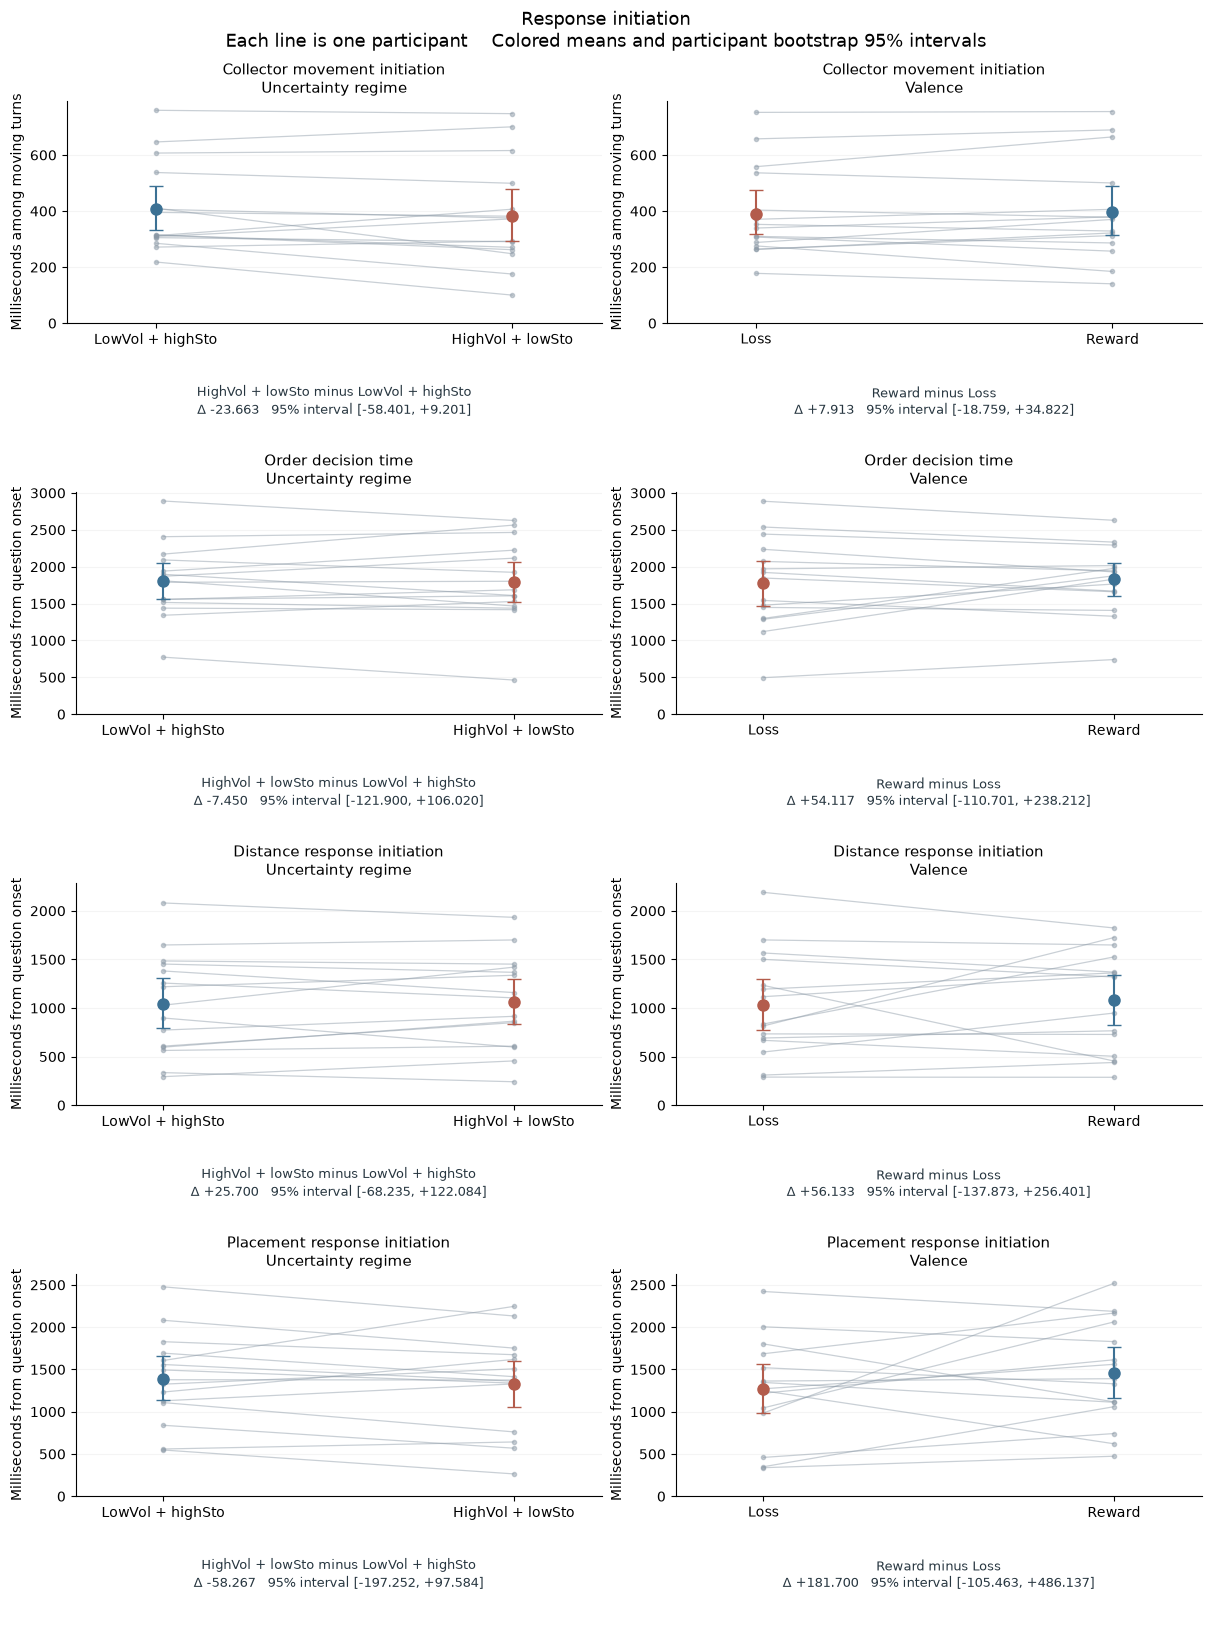

,comparison,outcome,First level,Second level,Difference and 95% interval,Higher / lower / tied,Participants
0,Uncertainty regime,Collector movement initiation,406.195,382.532,"-23.663 [-58.401, +9.201]",5 / 10 / 0,15
1,Uncertainty regime,Order decision time,1803.250,1795.800,"-7.450 [-121.900, +106.020]",8 / 7 / 0,15
2,Uncertainty regime,Distance response initiation,1041.367,1067.067,"+25.700 [-68.235, +122.084]",8 / 7 / 0,15
3,Uncertainty regime,Placement response initiation,1390.367,1332.100,"-58.267 [-197.252, +97.584]",5 / 10 / 0,15
4,Valence,Collector movement initiation,390.407,398.320,"+7.913 [-18.759, +34.822]",8 / 7 / 0,15
5,Valence,Order decision time,1772.467,1826.583,"+54.117 [-110.701, +238.212]",6 / 9 / 0,15
6,Valence,Distance response initiation,1026.150,1082.283,"+56.133 [-137.873, +256.401]",7 / 8 / 0,15
7,Valence,Placement response initiation,1270.383,1452.083,"+181.700 [-105.463, +486.137]",9 / 6 / 0,15


In [17]:
display(result['figures']['response_initiation'])
display(report.display_effects(result, ['game_initiation_ms','order_initiation_ms','distance_initiation_ms','placement_initiation_ms']))

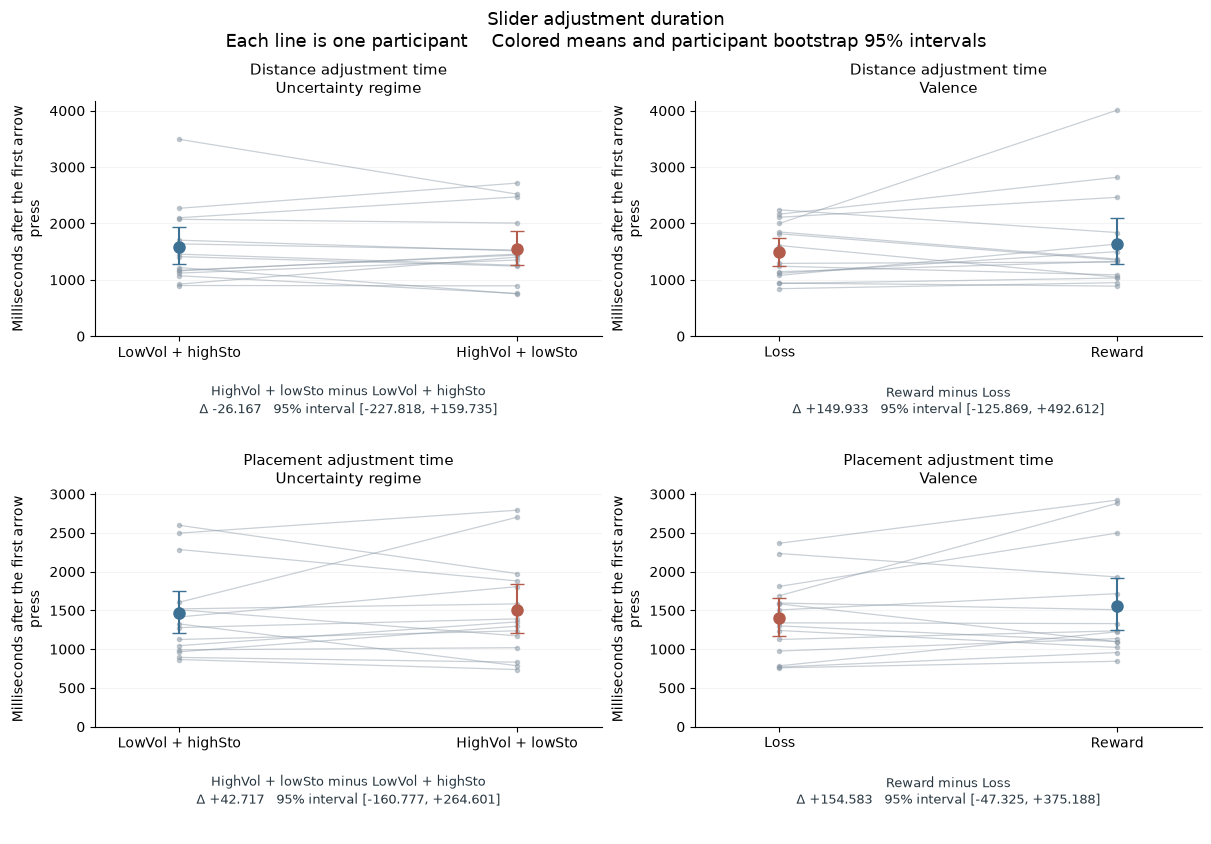

,comparison,outcome,First level,Second level,Difference and 95% interval,Higher / lower / tied,Participants
0,Uncertainty regime,Distance total response time,2691.733,2742.500,"+50.767 [-283.665, +360.371]",9 / 6 / 0,15
1,Uncertainty regime,Placement total response time,2967.900,2850.833,"-117.067 [-469.484, +234.489]",8 / 7 / 0,15
2,Valence,Distance total response time,2603.933,2830.300,"+226.367 [-133.470, +585.935]",10 / 5 / 0,15
3,Valence,Placement total response time,2773.767,3044.967,"+271.200 [-107.307, +651.442]",10 / 5 / 0,15


In [18]:
display(result['figures']['slider_timing'])
display(report.display_effects(result, ['distance_submission_ms','placement_submission_ms']))

,Game timing check,Observed
0,Moving turns,2480
1,Moving turns with initiation RT,2480
2,Stationary turns retained without initiation RT,520


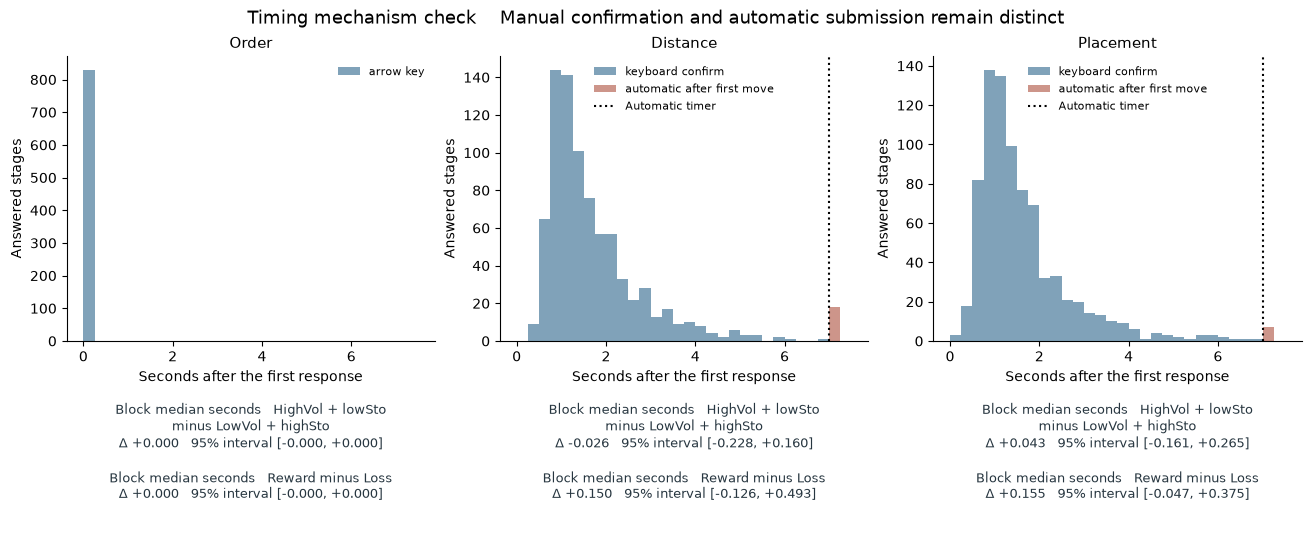

In [19]:
enc = result['tables']['encoding']
moving = pd.to_numeric(enc.num_moves, errors='coerce').gt(0)
display(pd.DataFrame({'Game timing check':['Moving turns','Moving turns with initiation RT','Stationary turns retained without initiation RT'],
    'Observed':[int(moving.sum()),int(enc.loc[moving,'rt_first_move_ms'].notna().sum()),int((~moving).sum())]}))
display(result['figures']['timing_mechanism'])

## Decisions for the next pilot

| Question | Current evidence | Design implication |
| --- | --- | --- |
| Were conditions delivered as coded | Recording and assignment checks agree | Preserve the technical foundation |
| Is adaptive learning differentiated | Small regime gain contrast and mixed individual directions | Prioritize validation within the intended jump design |
| Are memory responses sensitive | Order near chance and weak mean placement differentiation | Diagnose memory demands, interpretation and response use |
| Are there preliminary condition patterns | Some rating and accuracy differences remain visible | Treat them as exploratory until learning and measurement checks support the mechanism |

These are scientific judgments rather than automatic pass criteria or participant exclusions.

## Appendix on assignment and design support

Source arrays → Saved manifest → Observed condition and item records → Memory pairs and probes.

| Canonical condition | Valence | Regime |
| --- | --- | --- |
| A | Reward | LowVol plus highSto |
| B | Reward | HighVol plus lowSto |
| C | Loss | LowVol plus highSto |
| D | Loss | HighVol plus lowSto |

Latin groups use a participant ID hash and sequence offsets use a separate random draw. Equal recruitment counts are not guaranteed. Fixed tested pairs and change positions limit causal interpretations of gap and crossing comparisons.

,check,passed,checked,status
0,Latin square balances every condition at each position,4,4,Pass
1,Latin square balances first order carryover pairs,12,12,Pass
2,One saved design manifest per participant,15,15,Pass
3,Provider ID hash matches assigned group,15,15,Pass
4,Saved order matches assigned Latin row,15,15,Pass
5,Every participant receives all four conditions,15,15,Pass
6,Observed target and supply match assigned fixed arrays,15,15,Pass
7,Experimental item pool is unique and complete,15,15,Pass
8,Displayed condition labels follow the Latin assignment,60,60,Pass
9,Encoded items follow the saved item order,60,60,Pass


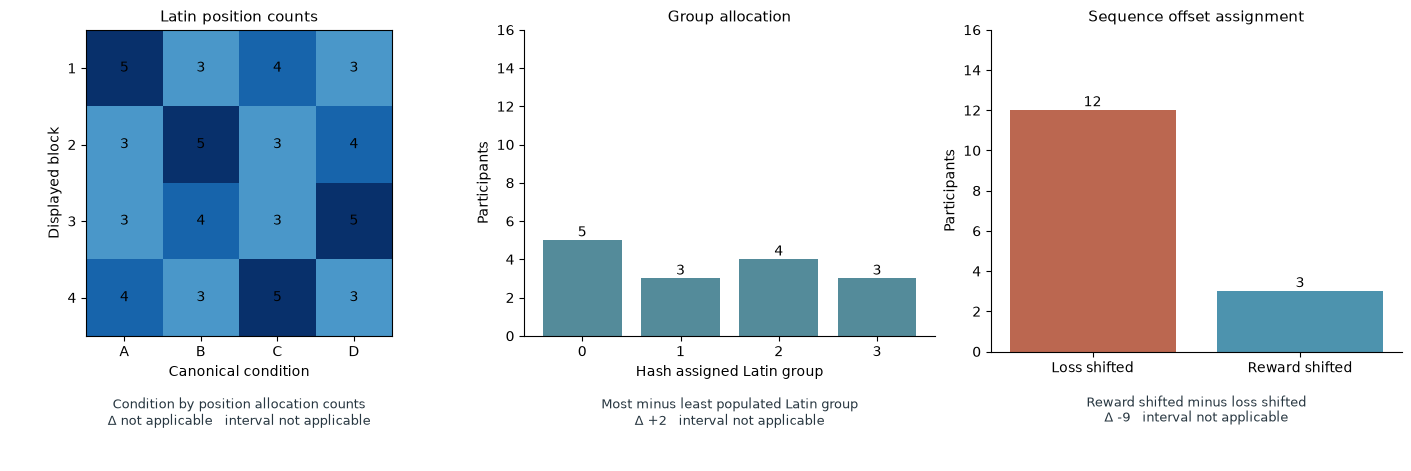

,Diagnostic,Observed,Possible records
0,Unique item orders,60,60
1,Unique memory pair orders,60,60
2,Unique left right patterns,60,60
3,Blocks with all eight probe selections observable,60,60


In [20]:
display(result['randomization']['checks'][['check','passed','checked','status']])
display(result['figures']['randomization'])
display(result['randomization']['diversity'])

### Displayed block position sensitivity

Only 3 participants received shifted reward sequences and 12 received shifted loss sequences. This descriptive adjustment checks displayed block position while retaining participant effects. It does not resolve every possible sequence effect.

In [21]:
display(result['sensitivity'].rename(columns={'mean':'Unadjusted difference','period_adjusted_difference':'Period adjusted difference'}).round(4))

,comparison,metric,Period adjusted difference,Unadjusted difference
0,Valence,update_slope,-0.0541,-0.0535
1,Uncertainty regime,update_slope,0.0246,0.0272
2,Valence,order_accuracy,0.0061,0.0071
3,Uncertainty regime,order_accuracy,0.0407,0.0405
4,Valence,distance_mean,6.5309,6.2690
5,Uncertainty regime,distance_mean,-1.8442,-2.8500
6,Valence,placement_mae_pp,-1.6145,-1.5056
7,Uncertainty regime,placement_mae_pp,-1.2900,-1.4824


## Reproducibility and separate mouse report

[Mouse acquisition and trajectories](../mouse_qc/Pilot1_mouse_analysis.ipynb) use the same cohort in their own notebook. Main figures and private joined tables are exported to `analysis/data/Pilot1/derived/group_analysis`. Earlier report versions remain in the private archive.

The published learning reference contains aggregate data, source hashes and the author code commit. Normal execution is offline. No latent model fitting, new significance tests or outcome based exclusions were added. Participant identifiers do not appear in displayed reports.

In [22]:
display(report.write_provenance(ROOT, BATCH, ROOT / 'analysis/drone_task/Pilot1_analysis.ipynb'))

,Material,Policy
0,Analysis helpers,SHA256 recorded
1,Executed notebook,Run with drone-design kernel
2,Private outputs,Retain joins in ignored batch folder
3,Raw source files,Preserved without modification
